# Estimacion del riesgo de paralizacion de obras publicas: proyecto final

**Problema**: clasificacion binaria desbalanceada (~7% clase positiva). `flg_opa_incumplimiento_contractual = 1` si la obra publica se paralizo por incumplimiento contractual, `0` en caso contrario. La probabilidad predicha `P(Y=1|X)` se interpreta como una medida cuantitativa de riesgo de paralizacion para priorizar el seguimiento de obras en ejecucion.

**Diferencia metodologica clave frente a los notebooks previos**: en `03`/`04` el `ColumnTransformer` (target encoding, WOE, one-hot) se ajustaba **una sola vez** sobre todo el train antes de la validacion cruzada, lo cual es una fuga de datos leve entre folds. Aqui el preprocesamiento se coloca **dentro de un `Pipeline` de scikit-learn junto con el clasificador**, de modo que la validacion cruzada anidada (seccion 5) ajusta los encoders de forma independiente en cada fold — esto es lo que en el roadmap original de `03_feature_engineering.ipynb` se dejo pendiente como `M3`.

## 0. Configuracion y reproducibilidad

Se fija una semilla global (`RANDOM_STATE`) reutilizada en todo estimador/particionador con componente aleatorio (`RandomForestClassifier`, solver `saga` de `LogisticRegression`). Las particiones de validacion cruzada temporal (`TimeSeriesSplit`) son deterministas por construccion (no usan aleatoriedad ni shuffle), lo cual es intencional: el orden temporal de los datos debe respetarse.

In [1]:
import sys
from configparser import ConfigParser
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
sns.set_theme(style="whitegrid")

# Agregar 'src' al path para importar los modulos del proyecto
project_root = Path.cwd().resolve().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.db.connection import PostgresConnection
from src.eda import missing_values_report
from src.evaluation import (
    analizar_umbrales,
    graficar_umbrales,
    importancia_arbol,
    importancia_lineal_sklearn,
    reporte_evaluacion,
)
from src.features import build_preprocessor


## 1. Carga y entendimiento de los datos

Fuente: tabla `r$_ds_obras_publicas_infobras` (PostgreSQL). 

- Se filtra a `nivel_gobierno = 'GOBIERNO NACIONAL'` debido a que esta población de entidades ejecutaras del gobierno nacional presentan mayor cantidad de paralizaciones y calidad en los datos.

- Se filtra a `marco = 'INVIERTE'` debido a que este nuevo marco de inversión publica presenta mejor calidad de los datos (pdt. El marco `SNIP` corresponde al marco normativo de la inversión antes de Invierte)

In [2]:
config_path = project_root / "configs" / "database.ini"
config = ConfigParser()
config.read(config_path)

pg_conn = PostgresConnection(
    host=config.get("postgres", "host"),
    port=config.getint("postgres", "port"),
    dbname=config.get("postgres", "dbname"),
    user=config.get("postgres", "user"),
    password=config.get("postgres", "password"),
)
conn = pg_conn.connect()

TARGET = "flg_opa_incumplimiento_contractual"
DATE_COL = "fecha_inicio_obra"

df_raw = pd.read_sql('SELECT * FROM "r$_ds_obras_publicas_infobras"', conn)
df = df_raw[
    (df_raw["nivel_gobierno"] == "GOBIERNO NACIONAL") & (df_raw["marco"] == "INVIERTE")
].copy()

print(f"Registros cargados: {len(df_raw):,}")
print(f"Registros tras el filtro: {len(df):,}")


C:\Users\yanfr\AppData\Local\Temp\ipykernel_5876\96224106.py:17: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_raw = pd.read_sql('SELECT * FROM "r$_ds_obras_publicas_infobras"', conn)


Registros cargados: 69,952
Registros tras el filtro: 2,646


### Resumen estadistico y distribucion del target

In [3]:
display(Markdown("**Distribucion del target (todo el universo filtrado)**"))
display(df[TARGET].value_counts(normalize=True).rename("proporcion").to_frame())

display(Markdown("**Resumen de `monto_aprobado_soles`**"))
display(df["monto_aprobado_soles"].describe().to_frame().T)


**Distribucion del target (todo el universo filtrado)**

,proporcion
flg_opa_incumplimiento_contractual,
0,0.925548
1,0.074452


**Resumen de `monto_aprobado_soles`**

,count,mean,std,min,25%,50%,75%,max
monto_aprobado_soles,2628.0,9.211674e+06,3.605973e+07,0.0,460497.69,1454460.395,5.682044e+06,685428264.0


In [4]:
# Reporte de valores faltantes en las columnas relevantes para este proyecto
columnas_interes = [
    "tipo_obra_nivel_2", "tipo_obra_nivel_3", "departamento", "provincia",
    "codigo_entidad", "sector_entidad", "naturaleza_obra", "tipo_formato",
    "monto_aprobado_soles", "monto_aprobacion_et", "n_obras_relacionadas_proyecto",
    DATE_COL, TARGET,
]
df_reducido = df[columnas_interes].copy()
display(missing_values_report(df_reducido))


,missing_count,missing_percentage
tipo_formato,95,3.59
monto_aprobacion_et,18,0.68
monto_aprobado_soles,18,0.68
departamento,1,0.04
provincia,1,0.04


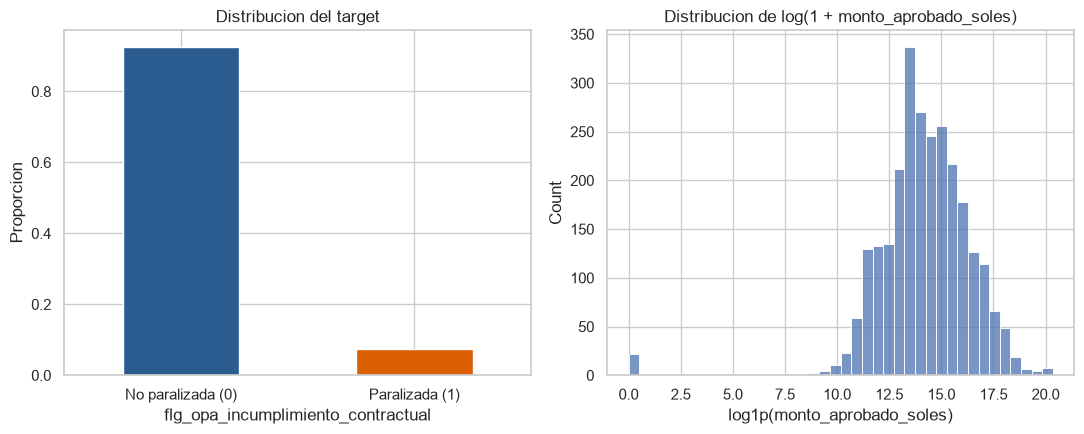

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

df[TARGET].value_counts(normalize=True).sort_index().plot(
    kind="bar", ax=axes[0], color=["#2b5c8f", "#d95f02"]
)
axes[0].set_title("Distribucion del target")
axes[0].set_xticklabels(["No paralizada (0)", "Paralizada (1)"], rotation=0)
axes[0].set_ylabel("Proporcion")

sns.histplot(np.log1p(df["monto_aprobado_soles"].dropna()), bins=40, ax=axes[1])
axes[1].set_title("Distribucion de log(1 + monto_aprobado_soles)")
axes[1].set_xlabel("log1p(monto_aprobado_soles)")

plt.tight_layout()
plt.show()


In [6]:
# Tasa de paralizacion cruda por departamento (sin ningun ajuste de train/test,
# solo para entender la relacion antes de modelar)
tasa_por_departamento = (
    df_reducido.groupby("departamento")[TARGET]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)
display(Markdown("**Tasa de paralizacion por departamento (top 10)**"))
display(tasa_por_departamento.head(10))


**Tasa de paralizacion por departamento (top 10)**

,mean,count
departamento,,
P C DEL CALLAO,0.181818,22
TUMBES,0.152778,72
MADRE DE DIOS,0.137931,29
ANCASH,0.134752,282
LA LIBERTAD,0.132979,188
JUNIN,0.098765,81
HUANCAVELICA,0.098361,61
AYACUCHO,0.090909,44
ICA,0.088889,45


## 2. Preprocesamiento de datos

Decisiones de limpieza (justificadas en comentarios dentro del codigo, replicando el analisis de outliers de `03_feature_engineering.ipynb` seccion `4. Pre-tratamiento de outliers`):

1. Eliminar registros con `monto_aprobado_soles` nulo (solo afecta a la clase mayoritaria, no distorsiona el desbalance).
2. `monto_aprobado_soles == 0` es un error de registro: se reemplaza por `monto_aprobacion_et` (el monto del expediente tecnico aprobado, una referencia razonable del monto real).
3. `monto_aprobado_soles == 1` es un valor invalido residual: se descarta ese registro.
4. La escala de `monto_aprobado_soles` es fuertemente asimetrica (ver histograma anterior): se trata con winsorizacion (p99) + log1p **dentro del pipeline de modelado** (no aqui), para que el limite de winsorizacion se aprenda solo con datos de entrenamiento.

In [7]:
# 1. Eliminar nulos en monto_aprobado_soles
n_antes = len(df_reducido)
df_reducido = df_reducido.dropna(subset=["monto_aprobado_soles"])
print(f"Eliminados por monto nulo: {n_antes - len(df_reducido):,}")

# 2. monto_aprobado_soles == 0 -> reemplazar por monto_aprobacion_et
mask_monto_cero = df_reducido["monto_aprobado_soles"] == 0
df_reducido.loc[mask_monto_cero, "monto_aprobado_soles"] = df_reducido.loc[
    mask_monto_cero, "monto_aprobacion_et"
]
print(f"Corregidos (monto == 0): {mask_monto_cero.sum():,}")

# 3. monto_aprobado_soles == 1 -> registro invalido, se descarta
n_antes = len(df_reducido)
df_reducido = df_reducido[df_reducido["monto_aprobado_soles"] != 1].copy()
print(f"Eliminados (monto == 1): {n_antes - len(df_reducido):,}")


Eliminados por monto nulo: 18
Corregidos (monto == 0): 22
Eliminados (monto == 1): 1


## 3. Proceso de Feature Engineering

**Variable temporal (lag / media movil).** Aunque cada fila representa un proyecto distinto (no es una serie de tiempo con una sola entidad repetida en el tiempo), varias obras comparten `codigo_entidad` a lo largo de los anios. Se construye una **tasa historica movil (expanding mean) de paralizacion por entidad**, usando en cada fila unicamente las obras *anteriores en el tiempo* de esa misma entidad (`shift(1)` excluye la fila actual): es el analogo, para datos panel, de un lag/media movil en series de tiempo, y es estrictamente causal (no usa informacion futura) por lo que puede calcularse antes de la particion train/test sin fuga de datos. Para la primera obra de una entidad (sin historia previa) se usa la tasa historica global acumulada hasta esa fecha.

**Codificacion de variables categoricas** (ver seccion 5: se realiza **dentro** del pipeline de modelado, no aqui, para que se ajuste por fold en la validacion cruzada):

| Columnas | Metodo |
|---|---|
| `tipo_obra_nivel_2`, `tipo_obra_nivel_3`, `departamento`, `provincia` | Target encoding bayesiano (suavizado) |
| `codigo_entidad`, `sector_entidad` | WOE (suavizado) |
| `naturaleza_obra`, `tipo_formato` | One-hot |
| `monto_aprobado_soles` | Winsorizacion (p99) + log1p + estandarizacion |
| `n_obras_relacionadas_proyecto`, `tasa_historica_movil_entidad` | Estandarizacion |

In [8]:
df_reducido[DATE_COL] = pd.to_datetime(df_reducido[DATE_COL], errors="coerce")
df_reducido = df_reducido.dropna(subset=[DATE_COL, TARGET])
df_reducido = df_reducido.sort_values(DATE_COL).reset_index(drop=True)

# Media movil (expanding) causal de la tasa de paralizacion por entidad.
tasa_por_entidad_previa = (
    df_reducido.groupby("codigo_entidad")[TARGET]
    .apply(lambda serie: serie.expanding().mean().shift(1))
    .reset_index(level=0, drop=True)
)
tasa_global_previa = df_reducido[TARGET].expanding().mean().shift(1)

df_reducido["tasa_historica_movil_entidad"] = (
    tasa_por_entidad_previa.fillna(tasa_global_previa).fillna(df_reducido[TARGET].mean())
)

df_reducido[["codigo_entidad", DATE_COL, TARGET, "tasa_historica_movil_entidad"]].head(10)


,codigo_entidad,fecha_inicio_obra,flg_opa_incumplimiento_contractual,tasa_historica_movil_entidad
0,6012,2010-12-18,0,0.07499
1,6352,2012-08-25,0,0.00000
2,282,2012-12-28,0,0.00000
3,282,2012-12-28,0,0.00000
4,282,2013-02-26,0,0.00000
5,6012,2013-03-01,0,0.00000
6,284,2013-08-11,0,0.00000
7,312,2013-10-17,0,0.00000
8,6012,2014-04-08,0,0.00000
9,6012,2014-06-17,1,0.00000


In [9]:
# Definicion de los grupos de columnas usados por el preprocesador (seccion 5)
columnas_target_encoding = ["tipo_obra_nivel_2", "tipo_obra_nivel_3", "departamento", "provincia"]
columnas_woe = ["codigo_entidad", "sector_entidad"]
columnas_onehot = ["naturaleza_obra", "tipo_formato"]
columnas_monto = ["monto_aprobado_soles"]
columnas_numericas = ["n_obras_relacionadas_proyecto", "tasa_historica_movil_entidad"]

columnas_features = (
    columnas_target_encoding + columnas_woe + columnas_onehot
    + columnas_monto + columnas_numericas
)


## 4. Definicion del esquema experimental

**Particion train/test**: temporal (no aleatoria). Se ordena por `fecha_inicio_obra` y se separa el 65% mas antiguo para entrenamiento y el 35% mas reciente para prueba, ya que el fenomeno es intrinsecamente temporal (se usa la historia de ejecuciones pasadas para estimar el riesgo de obras futuras); una particion aleatoria filtraria informacion del futuro hacia el pasado.

El test set queda completamente aislado hasta la evaluacion final (seccion 6). Toda la seleccion de modelo e hiperparametros (seccion 5) usa **solo el train**, con `TimeSeriesSplit` (los folds tambien respetan el orden temporal, sin mezclar pasado y futuro dentro de la validacion cruzada).

In [24]:
split_idx = int(len(df_reducido) * 0.62)
df_train = df_reducido.iloc[:split_idx].copy()
df_test = df_reducido.iloc[split_idx:].copy()

X_train = df_train[columnas_features]
y_train = df_train[TARGET]
X_test = df_test[columnas_features]
y_test = df_test[TARGET]

print(f"Train: {len(df_train):,} | {df_train[DATE_COL].min().date()} a {df_train[DATE_COL].max().date()} | tasa positiva: {y_train.mean():.4f}")
print(f"Test : {len(df_test):,} | {df_test[DATE_COL].min().date()} a {df_test[DATE_COL].max().date()} | tasa positiva: {y_test.mean():.4f}")


Train: 1,628 | 2010-12-18 a 2022-10-22 | tasa positiva: 0.0848
Test : 999 | 2022-10-22 a 2025-12-20 | tasa positiva: 0.0591


## 5. Entrenamiento de modelos: comparacion mediante validacion cruzada anidada

Se comparan dos familias de modelos, ambas envueltas en un unico `Pipeline` (`preprocesador` + `clasificador`) para que el preprocesamiento (incluyendo target encoding y WOE, que usan el target) se ajuste de forma independiente en cada fold:

- **Regresion logistica penalizada** (Elastic Net via `saga`): combina Lasso/Ridge, grid sobre `C` y `l1_ratio`.
- **Random Forest**: grid sobre `n_estimators`, `max_depth`, `min_samples_leaf`.

**Anidamiento**: `GridSearchCV` (bucle interno, `TimeSeriesSplit` de 3 folds, selecciona hiperparametros por PR-AUC) se evalua a su vez con `cross_validate` (bucle externo, `TimeSeriesSplit` de 5 folds). El bucle externo nunca ve los datos usados para elegir hiperparametros en ese mismo fold, lo que da una estimacion honesta del desempenio de cada familia de modelos antes de comprometerse con una.

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_validate
from sklearn.metrics import make_scorer, fbeta_score

preprocesador = build_preprocessor(
    amount_log_columns=columnas_monto,
    numeric_columns=columnas_numericas,
    categorical_columns=columnas_onehot,
    target_encoded_columns=columnas_target_encoding,
    woe_columns=columnas_woe,
)

pipeline_logit = Pipeline(steps=[
    ("preprocesador", preprocesador),
    ("clasificador", LogisticRegression(
        solver="saga", penalty="elasticnet", class_weight="balanced",
        max_iter=3000, random_state=RANDOM_STATE,
    )),
])
grid_logit = {
    "clasificador__C": [0.01, 0.1, 1.0, 10.0],
    "clasificador__l1_ratio": [0.0, 0.5, 1.0],
}

pipeline_rf = Pipeline(steps=[
    ("preprocesador", preprocesador),
    ("clasificador", RandomForestClassifier(
        class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1,
    )),
])
grid_rf = {
    "clasificador__n_estimators": [200, 500],
    "clasificador__max_depth": [None, 6, 10],
    "clasificador__min_samples_leaf": [1, 5],
}

candidatos = {
    "Regresion logistica (Elastic Net)": (pipeline_logit, grid_logit),
    "Random Forest": (pipeline_rf, grid_rf),
}


In [26]:
cv_interno = TimeSeriesSplit(n_splits=3)
cv_externo = TimeSeriesSplit(n_splits=5)

scoring_externo = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "f2": make_scorer(fbeta_score, beta=2, zero_division=0),
}

resultados_nested_cv = {}

for nombre, (pipeline, grid) in candidatos.items():
    busqueda_interna = GridSearchCV(
        pipeline, param_grid=grid, cv=cv_interno,
        scoring="average_precision", n_jobs=-1, refit=True,
    )
    resultado = cross_validate(
        busqueda_interna, X_train, y_train,
        cv=cv_externo, scoring=scoring_externo, n_jobs=1,
        return_estimator=False,
    )
    resultados_nested_cv[nombre] = resultado
    print(f"{nombre}: PR-AUC = {resultado['test_pr_auc'].mean():.4f} +/- {resultado['test_pr_auc'].std():.4f}")


c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\ws\formacion\uni-mi

Regresion logistica (Elastic Net): PR-AUC = 0.2404 +/- 0.0982
Random Forest: PR-AUC = 0.2636 +/- 0.1314


In [27]:
resumen_nested_cv = pd.DataFrame({
    nombre: {
        "roc_auc_media": resultado["test_roc_auc"].mean(),
        "roc_auc_std": resultado["test_roc_auc"].std(),
        "pr_auc_media": resultado["test_pr_auc"].mean(),
        "pr_auc_std": resultado["test_pr_auc"].std(),
        "f2_media": resultado["test_f2"].mean(),
        "f2_std": resultado["test_f2"].std(),
    }
    for nombre, resultado in resultados_nested_cv.items()
}).T

display(Markdown("**Comparacion de familias de modelos (validacion cruzada anidada, sobre train)**"))
display(resumen_nested_cv.round(4))


**Comparacion de familias de modelos (validacion cruzada anidada, sobre train)**

,roc_auc_media,roc_auc_std,pr_auc_media,pr_auc_std,f2_media,f2_std
Regresion logistica (Elastic Net),0.6912,0.0979,0.2404,0.0982,0.3349,0.1438
Random Forest,0.7422,0.0665,0.2636,0.1314,0.1620,0.1203


### Seleccion del modelo finalista

Se elige la familia con mejor `pr_auc_media` en la validacion cruzada anidada (metrica principal de seleccion: ver justificacion de metricas en la seccion 6).

In [28]:
nombre_finalista = resumen_nested_cv["pr_auc_media"].idxmax()
pipeline_finalista, grid_finalista = candidatos[nombre_finalista]
print(f"Modelo finalista: {nombre_finalista}")


Modelo finalista: Random Forest


## 6. Busqueda de hiperparametros del modelo finalista

Con la familia ganadora, se repite la busqueda de hiperparametros (`GridSearchCV`, mismo `TimeSeriesSplit` de 3 folds, `average_precision`) pero ahora sobre **todo el train**, para aprovechar toda la informacion disponible antes de la evaluacion final. El test set sigue sin usarse en esta busqueda.

In [29]:
busqueda_final = GridSearchCV(
    pipeline_finalista, param_grid=grid_finalista, cv=TimeSeriesSplit(n_splits=3),
    scoring="average_precision", n_jobs=-1, refit=True,
)
busqueda_final.fit(X_train, y_train)

print(f"Mejores hiperparametros: {busqueda_final.best_params_}")
print(f"Mejor PR-AUC (CV interna sobre train): {busqueda_final.best_score_:.4f}")

modelo_final = busqueda_final.best_estimator_


Mejores hiperparametros: {'clasificador__max_depth': 6, 'clasificador__min_samples_leaf': 5, 'clasificador__n_estimators': 200}
Mejor PR-AUC (CV interna sobre train): 0.2417


### Evaluacion final sobre el test (umbral=0.5)

**Metricas escogidas**: ROC AUC y PR AUC (rendimiento global, independiente del umbral; PR AUC es mas informativa que ROC AUC bajo fuerte desbalance de clases), Gini (`2*ROC AUC - 1`, escala habitual en modelos de riesgo/scoring), precision/recall/F1 (desempenio a un umbral fijo) y F2 (pondera el recall el doble que la precision: en este problema, no detectar una obra que sí se va a paralizar -falso negativo- es mas costoso que investigar una obra que finalmente no se paraliza -falso positivo-).

**Metricas globales - Modelo finalista - Random Forest (test, umbral=0.5)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.638  |
| pr_auc    |  0.1557 |
| gini      |  0.2759 |
| precision |  0.1429 |
| recall    |  0.4407 |
| f1        |  0.2158 |
| f2        |  0.311  |

**Reporte de clasificacion - Modelo finalista - Random Forest (test, umbral=0.5)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.96  |    0.834 |      0.892 |   940     |
| 1            |       0.143 |    0.441 |      0.216 |    59     |
| accuracy     |       0.811 |    0.811 |      0.811 |     0.811 |
| macro avg    |       0.551 |    0.637 |      0.554 |   999     |
| weighted avg |       0.911 |    0.811 |      0.852 |   999     |

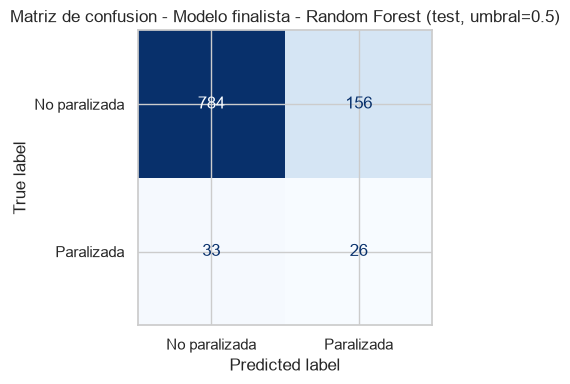

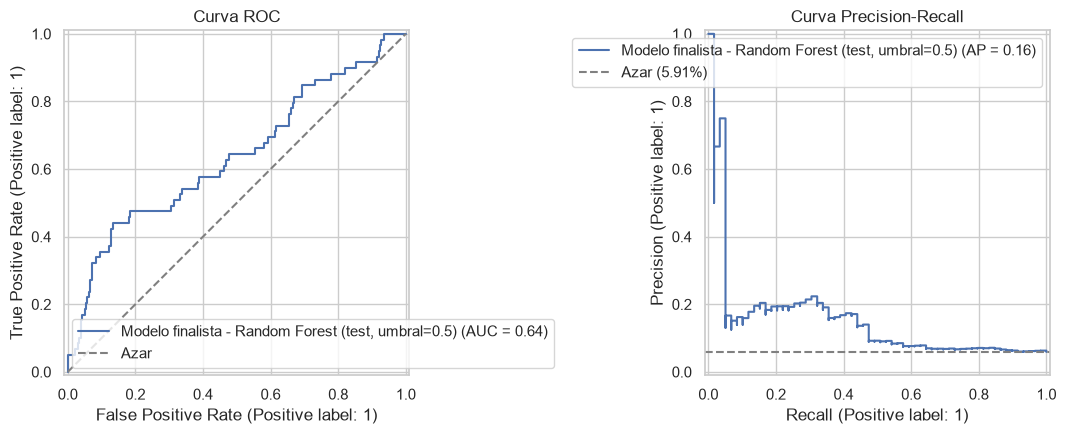

In [30]:
y_pred_final = modelo_final.predict(X_test)
y_proba_final = modelo_final.predict_proba(X_test)[:, 1]

metrics_final = reporte_evaluacion(
    y_test, y_pred_final, y_proba_final,
    nombre_modelo=f"Modelo finalista - {nombre_finalista} (test, umbral=0.5)"
)


### Analisis y seleccion del umbral de decision

Dado el desbalance de clases y que el costo de negocio favorece priorizar el recall (F2), se analiza el desempenio en una grilla de umbrales de decision en vez de usar el 0.5 por defecto.

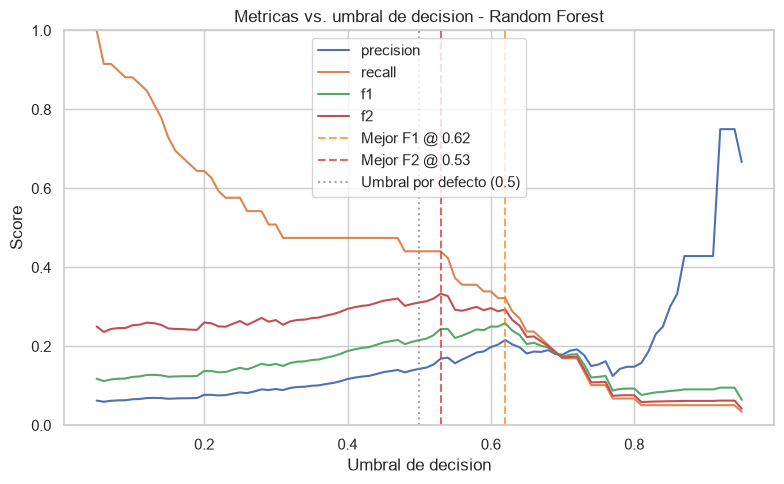

**Mejor umbral por F2 (prioriza recall)**

|   umbral |   precision |   recall |     f1 |     f2 |
|---------:|------------:|---------:|-------:|-------:|
|     0.53 |      0.1688 |   0.4407 | 0.2441 | 0.3333 |

**Metricas globales - Modelo finalista - Random Forest (test, umbral=0.53)**

|           |   valor |
|:----------|--------:|
| roc_auc   |  0.638  |
| pr_auc    |  0.1557 |
| gini      |  0.2759 |
| precision |  0.1688 |
| recall    |  0.4407 |
| f1        |  0.2441 |
| f2        |  0.3333 |

**Reporte de clasificacion - Modelo finalista - Random Forest (test, umbral=0.53)**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| 0            |       0.961 |    0.864 |      0.91  |   940     |
| 1            |       0.169 |    0.441 |      0.244 |    59     |
| accuracy     |       0.839 |    0.839 |      0.839 |     0.839 |
| macro avg    |       0.565 |    0.652 |      0.577 |   999     |
| weighted avg |       0.914 |    0.839 |      0.87  |   999     |

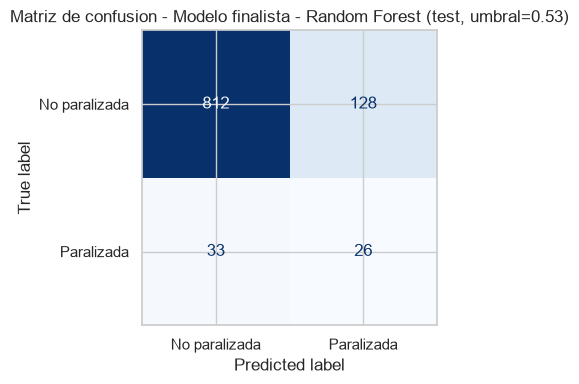

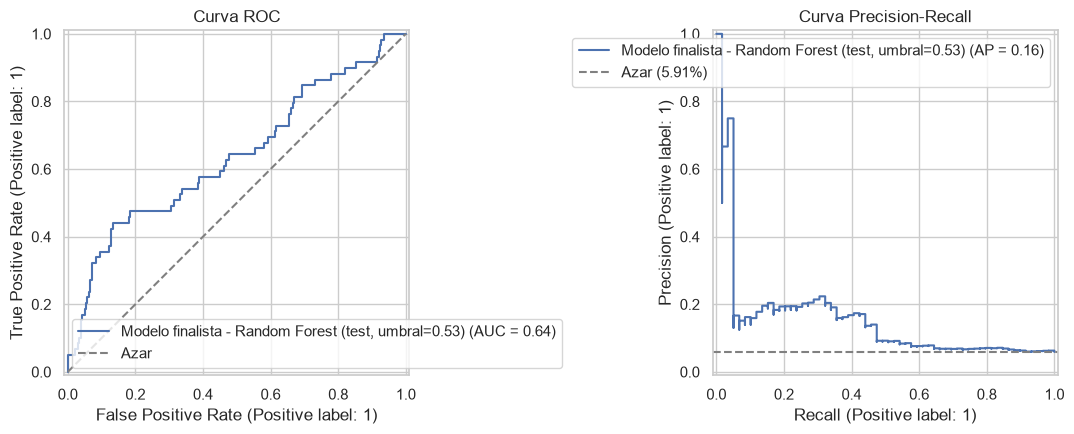

In [31]:
umbrales_final = analizar_umbrales(y_test, y_proba_final)
mejor_f1_final, mejor_f2_final = graficar_umbrales(umbrales_final, nombre_modelo=nombre_finalista)

display(Markdown("**Mejor umbral por F2 (prioriza recall)**"))
display(Markdown(mejor_f2_final.to_frame().T.round(4).to_markdown(index=False)))

UMBRAL_DECISION_FINAL = mejor_f2_final["umbral"]
y_pred_final_umbral = (y_proba_final >= UMBRAL_DECISION_FINAL).astype(int)

metrics_final_umbral = reporte_evaluacion(
    y_test, y_pred_final_umbral, y_proba_final,
    nombre_modelo=f"Modelo finalista - {nombre_finalista} (test, umbral={UMBRAL_DECISION_FINAL:.2f})"
)


### Analisis de importancia de variables

Interpretacion segun el tipo de modelo finalista: si es la regresion logistica, se muestran los coeficientes y los **odds ratios** (`exp(coeficiente)`: cuanto se multiplican las probabilidades de paralizacion por cada unidad de la variable, manteniendo lo demas constante); si es Random Forest, se muestra la importancia por reduccion de impureza.

In [32]:
nombres_features_final = modelo_final.named_steps["preprocesador"].get_feature_names_out()
clasificador_final = modelo_final.named_steps["clasificador"]

if isinstance(clasificador_final, LogisticRegression):
    tabla_importancia = importancia_lineal_sklearn(
        clasificador_final, nombres_features_final, nombre_modelo=nombre_finalista
    )
    tabla_importancia["odds_ratio"] = np.exp(tabla_importancia["coeficiente"])
    display(Markdown("**Odds ratios**"))
    display(tabla_importancia[["variable", "coeficiente", "odds_ratio"]].round(4))
else:
    tabla_importancia = importancia_arbol(
        clasificador_final, nombres_features_final, nombre_modelo=nombre_finalista
    )


**Variables e importancia (impureza) - Random Forest**

| variable                                           |   importancia |
|:---------------------------------------------------|--------------:|
| woe__codigo_entidad_woe                            |        0.2178 |
| amount_log__monto_aprobado_soles_winsor_log        |        0.1801 |
| target_encoded__provincia_target_enc               |        0.1544 |
| numeric_standard__tasa_historica_movil_entidad     |        0.1056 |
| target_encoded__tipo_obra_nivel_3_target_enc       |        0.0728 |
| woe__sector_entidad_woe                            |        0.057  |
| target_encoded__tipo_obra_nivel_2_target_enc       |        0.0567 |
| categorical__naturaleza_obra_Instalación           |        0.0375 |
| target_encoded__departamento_target_enc            |        0.0342 |
| categorical__naturaleza_obra_Rehabilitación        |        0.023  |
| categorical__tipo_formato_2                        |        0.0161 |
| categorical__tipo_formato_5                        |        0.0123 |
| categorical__tipo_formato_1                        |        0.0078 |
| categorical__naturaleza_obra_Construcción/Creación |        0.0068 |
| categorical__naturaleza_obra_Mejoramiento          |        0.0052 |
| categorical__naturaleza_obra_Remodelación          |        0.0035 |
| categorical__naturaleza_obra_Renovación            |        0.0034 |
| categorical__naturaleza_obra_Reconstrucción        |        0.0034 |
| categorical__naturaleza_obra_Ampliación            |        0.0014 |
| categorical__naturaleza_obra_Reparación            |        0.0006 |
| categorical__naturaleza_obra_infrequent_sklearn    |        0.0005 |
| numeric_standard__n_obras_relacionadas_proyecto    |        0      |

## 7. Reproducibilidad

- Semilla unica `RANDOM_STATE = 42` reutilizada en todos los estimadores con componente aleatoria.
- Particion train/test y validacion cruzada (`TimeSeriesSplit`) deterministas por orden temporal, sin shuffle.
- Todo el preprocesamiento (winsorizacion+log, estandarizacion, target encoding, WOE, one-hot) vive dentro de un unico `Pipeline` de scikit-learn (`src/features/preprocessing.py`), ajustado exclusivamente con datos de entrenamiento en cada fold/particion — evita fuga de datos y hace que `fit`/`predict` sean reproducibles de punta a punta.
- Funciones reutilizables (encoders, pipelines, metricas, graficos de umbral, tablas de importancia) centralizadas en `src/features/` y `src/evaluation/`, sin logica duplicada entre notebooks.
- Conexion a base de datos parametrizada via `configs/database.ini` (sin credenciales hardcodeadas en el notebook).

In [ ]:
if pg_conn:
    pg_conn.close()
    print("Conexion a PostgreSQL cerrada")
